# VAE for Bearing Vibration
**Author:** Min Khaung Min Lwin

**Dataset:** Paderborn Bearing Dataset on Zenodo (DOI 10.5281/zenodo.15845309), https://zenodo.org/records/15845309 .

This dataset was created by Lessmeier et al. (2016) at Paderborn University, and the Zenodo upload is a copy. Later these are re-upload by Jurgen van den Hoogen (Osnabrück University), and published July 2025 under a CC BY 4.0 licence for copy.

**Task type:** I'll train a 1D-convolutional VAE on vibration windows from the Paderborn University bearing dataset. The training will be on healthy K001–K004, test on unseen healthy K005–K006 and on real damage KA04/KA15/KA16 (outer race) and KI04/KI14/KI16 (inner race).

With this we can generate new signals, explore the latent space, and test whether reconstruction error separates healthy from damaged bearings. 


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
from scipy.io import loadmat
from pathlib import Path

DATA = Path("data/paderborn")
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(torch.__version__, device)

f = DATA / "K001" / "N15_M07_F10_K001_1.mat"
m = loadmat(f, simplify_cells=True)
print([k for k in m if not k.startswith("__")])
rec = m[f.stem]
print(type(rec), rec.keys() if isinstance(rec, dict) else "")
for ch in rec["Y"]:
    print(ch["Name"], np.asarray(ch["Data"]).shape)

2.15.0 mps
['N15_M07_F10_K001_1']
<class 'dict'> dict_keys(['Info', 'X', 'Y', 'Description'])
force (16001,)
phase_current_1 (256001,)
phase_current_2 (256001,)
speed (16001,)
temp_2_bearing_module (5,)
torque (16001,)
vibration_1 (256001,)


#### Note: I will load every file and look at the signals

In [2]:
BEARINGS = {"K001": "healthy", "K002": "healthy", "K003": "healthy", "K004": "healthy",
            "K005": "healthy", "K006": "healthy",
            "KA04": "outer_race", "KA15": "outer_race", "KA16": "outer_race",
            "KI04": "inner_race", "KI14": "inner_race", "KI16": "inner_race"}
FS = 64000

def load_vibration(path):
    """Return the vibration_1 channel of one Paderborn recording as float32."""
    rec = loadmat(path, simplify_cells=True)[path.stem]
    ch = next(c for c in rec["Y"] if c["Name"] == "vibration_1")
    return np.asarray(ch["Data"], dtype=np.float32)

signals, rows = {}, []
for b, label in BEARINGS.items():
    for f in sorted((DATA / b).glob("N15_M07_F10_*.mat")):
        x = load_vibration(f)
        signals[f.stem] = x
        rows.append({"file": f.stem, "bearing": b, "label": label, "n": len(x),
                     "rms": float(np.sqrt(np.mean(x**2))), "kurtosis": float(pd.Series(x).kurt())})
meta = pd.DataFrame(rows)
print(len(meta), "recordings")
meta.groupby(["label", "bearing"])[["n", "rms", "kurtosis"]].mean().round(3)

240 recordings


n    rms  kurtosis
label      bearing                            
healthy    K001     256261.75  0.403    10.687
           K002     257121.15  0.230    12.033
           K003     256760.60  0.362    12.788
           K004     256001.00  0.171     2.118
           K005     256259.45  0.199     1.215
           K006     256903.45  0.381    11.760
inner_race KI04     256181.40  0.365     2.202
           KI14     257635.05  0.227     0.806
           KI16     256932.10  0.390     2.081
outer_race KA04     256385.70  0.484     2.621
           KA15     256000.75  0.208     1.363
           KA16     256269.55  0.600     3.012

In [3]:
import os; os.makedirs("figures", exist_ok=True)

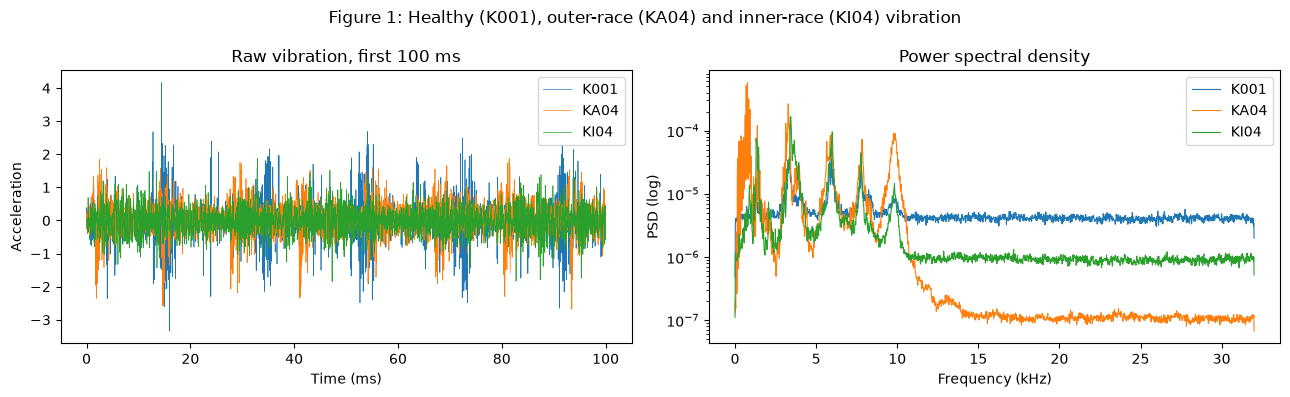

In [4]:
# Figure 1: raw vibration (first 0.1 s) and average spectrum for one bearing per class
from scipy.signal import welch
examples = ["N15_M07_F10_K001_1", "N15_M07_F10_KA04_1", "N15_M07_F10_KI04_1"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in examples:
    x = signals[name]
    t = np.arange(6400) / FS
    axes[0].plot(t * 1000, x[:6400], lw=0.5, label=name.split("_")[-2])
    f, p = welch(x, fs=FS, nperseg=4096)
    axes[1].semilogy(f / 1000, p, lw=0.8, label=name.split("_")[-2])
axes[0].set_title("Raw vibration, first 100 ms"); axes[0].set_xlabel("Time (ms)"); axes[0].set_ylabel("Acceleration")
axes[1].set_title("Power spectral density"); axes[1].set_xlabel("Frequency (kHz)"); axes[1].set_ylabel("PSD (log)")
for ax in axes: ax.legend()
plt.suptitle("Figure 1: Healthy (K001), outer-race (KA04) and inner-race (KI04) vibration")
plt.tight_layout(); plt.savefig("figures/fig1_samples.png", dpi=150); plt.show()

#### Now we will check whether these patterns follow the bearing or the session.

In [5]:
from scipy.signal import welch
diag = []
for _, r in meta.iterrows():
    f, p = welch(signals[r["file"]], fs=FS, nperseg=4096)
    diag.append({"bearing": r["bearing"], "label": r["label"],
                 "log_floor_15_30k": np.log10(p[(f > 15000) & (f < 30000)].mean()),
                 "log_band_0_10k": np.log10(p[f < 10000].mean()),
                 "kurtosis": r["kurtosis"]})
diag = pd.DataFrame(diag)
diag.groupby(["label", "bearing"]).agg(["mean", "std"]).round(2)

log_floor_15_30k       log_band_0_10k       kurtosis      
                               mean   std           mean   std     mean   std
label      bearing                                                           
healthy    K001               -5.40  0.02          -5.14  0.01    10.69  0.48
           K002               -6.08  0.02          -5.47  0.01    12.03  0.76
           K003               -5.46  0.01          -5.27  0.01    12.79  0.69
           K004               -6.60  0.01          -5.64  0.01     2.12  0.11
           K005               -6.57  0.01          -5.48  0.01     1.21  0.10
           K006               -5.44  0.02          -5.20  0.01    11.76  0.50
inner_race KI04               -5.96  0.11          -4.97  0.02     2.20  0.26
           KI14               -6.64  0.02          -5.35  0.01     0.81  0.11
           KI16               -6.53  0.01          -4.85  0.01     2.08  0.10
outer_race KA04               -6.94  0.02          -4.65  0.01     2.62  0.11
           KA15               -6.59  0.05          -5.46  0.01     1.36  0.21
           KA16               -6.77  0.04          -4.49  0.04     3.01  1.70

#### We'll build the spectrum dataset

In [6]:
WIN, NBIN_AVG, FMAX = 4096, 5, 10000      # 64 ms windows; 15.6 Hz bins averaged 5 at a time = 78 Hz; keep 0–10 kHz

def window_spectra(x):
    """Cut a signal into non-overlapping windows and return log power spectra (0–10 kHz, 128 bins)."""
    n = len(x) // WIN
    w = x[: n * WIN].reshape(n, WIN) * np.hanning(WIN)
    p = np.abs(np.fft.rfft(w, axis=1)) ** 2
    keep = int(FMAX / (FS / WIN))                       # 640 bins up to 10 kHz
    p = p[:, 1: keep + 1].reshape(n, -1, NBIN_AVG).mean(axis=2)   # drop DC, average to 128 bins
    return np.log10(p + 1e-12).astype(np.float32)

spec, spec_meta = [], []
for _, r in meta.iterrows():
    s = window_spectra(signals[r["file"]])
    spec.append(s); spec_meta += [{"bearing": r["bearing"], "label": r["label"], "file": r["file"]}] * len(s)
spec = np.concatenate(spec); spec_meta = pd.DataFrame(spec_meta)
print(spec.shape)
spec_meta.groupby(["label", "bearing"]).size()

(14903, 128)


label       bearing
healthy     K001       1240
            K002       1245
            K003       1243
            K004       1240
            K005       1240
            K006       1242
inner_race  KI04       1240
            KI14       1247
            KI16       1244
outer_race  KA04       1241
            KA15       1240
            KA16       1241
dtype: int64

#### Prediction before training

If the VAE mainly learns overall loudness (the level of the 0–10 kHz spectrum), **KI14 and KA15 will be the hardest damaged bearings to detect.**

Why: in the diagnostics table above, their mean log power in the 0–10 kHz band (KI14 −5.35, KA15 −5.46) sits inside the range of the healthy training bearings K001–K004 (−5.64 to −5.14). The other damaged bearings are all louder than any healthy one (KI04 −4.97, KI16 −4.85, KA04 −4.65, KA16 −4.49), so a loudness-only model would flag them easily.

So if KI14 and KA15 do score close to healthy after training, the model is mostly reacting to loudness. If they are still separated well, it is picking up the shape of the spectrum, not just its level.

#### Next step, we will split and standardise

In [7]:
rec_no = spec_meta["file"].str.split("_").str[-1].astype(int)
train_b = ["K001", "K002", "K003", "K004"]
is_train_b = spec_meta["bearing"].isin(train_b)

tr = is_train_b & (rec_no <= 16)          # training: recordings 1–16 of K001–K004
va = is_train_b & (rec_no > 16)           # validation: recordings 17–20 of the same bearings (monitoring only)
te = ~is_train_b                          # test: K005–K006 (healthy) and all damaged bearings, never seen

mu, sd = spec[tr].mean(axis=0), spec[tr].std(axis=0) + 1e-6   # per-bin statistics from training data only
Z = (spec - mu) / sd
print(tr.sum(), va.sum(), te.sum())

3970 998 9935


------

#### The VAE

In [8]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class SpecVAE(nn.Module):
    """1D-convolutional VAE for 128-bin log power spectra."""
    def __init__(self, latent=8):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv1d(1, 16, 5, stride=2, padding=2), nn.LeakyReLU(0.2),   # 128 -> 64
            nn.Conv1d(16, 32, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 64 -> 32
            nn.Conv1d(32, 64, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 32 -> 16
            nn.Flatten())
        self.mu, self.logvar = nn.Linear(64 * 16, latent), nn.Linear(64 * 16, latent)
        self.fc = nn.Linear(latent, 64 * 16)
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 16 -> 32
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 32 -> 64
            nn.ConvTranspose1d(16, 1, 4, stride=2, padding=1))                      # 64 -> 128

    def encode(self, x):
        h = self.enc(x); return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.dec(self.fc(z).view(-1, 64, 16))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # reparameterisation trick
        return self.decode(z), mu, logvar

def vae_loss(x, xr, mu, logvar, beta=1.0):
    """Negative ELBO per sample: Gaussian reconstruction (sum of squared errors) + beta * KL."""
    rec = ((x - xr) ** 2).sum(dim=(1, 2)).mean()
    kl = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)).mean()
    return rec + beta * kl, rec, kl

def to_ds(mask):
    return TensorDataset(torch.tensor(Z[mask.values]).unsqueeze(1))

torch.manual_seed(0)
vae = SpecVAE(latent=8).to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
train_loader = DataLoader(to_ds(tr), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(0))
val_x = to_ds(va).tensors[0].to(device)

hist = []
for ep in range(60):
    vae.train(); tot = np.zeros(3); n = 0
    for (xb,) in train_loader:
        xb = xb.to(device); xr, m_, lv = vae(xb)
        loss, rec, kl = vae_loss(xb, xr, m_, lv)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += np.array([loss.item(), rec.item(), kl.item()]) * len(xb); n += len(xb)
    vae.eval()
    with torch.no_grad():
        vl, vr, vk = vae_loss(val_x, *vae(val_x))
    hist.append({"epoch": ep + 1, "train_loss": tot[0] / n, "train_rec": tot[1] / n, "train_kl": tot[2] / n,
                 "val_loss": vl.item(), "val_rec": vr.item(), "val_kl": vk.item()})
hist = pd.DataFrame(hist)
print(sum(p.numel() for p in vae.parameters()), "parameters")
hist.iloc[[0, 9, 29, 59]].round(2)

48961 parameters


,epoch,train_loss,train_rec,train_kl,val_loss,val_rec,val_kl
0,1,104.40,99.73,4.67,78.56,72.76,5.80
9,10,64.35,59.60,4.75,63.83,59.50,4.33
29,30,62.02,56.92,5.10,62.13,57.24,4.89
59,60,61.61,56.48,5.13,61.79,57.01,4.78


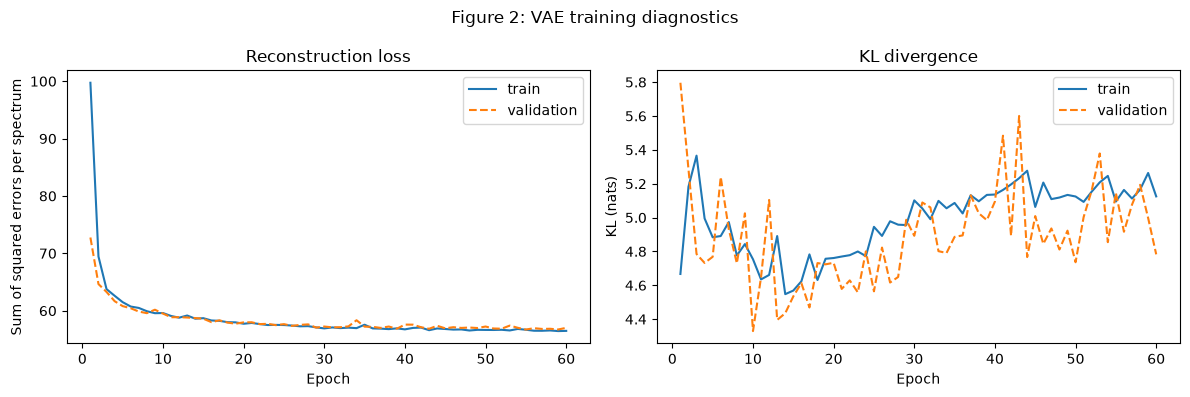

In [9]:
# Figure 2: training diagnostics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_rec"], label="train"); axes[0].plot(hist["epoch"], hist["val_rec"], "--", label="validation")
axes[0].set_title("Reconstruction loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Sum of squared errors per spectrum")
axes[1].plot(hist["epoch"], hist["train_kl"], label="train"); axes[1].plot(hist["epoch"], hist["val_kl"], "--", label="validation")
axes[1].set_title("KL divergence"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("KL (nats)")
for ax in axes: ax.legend()
plt.suptitle("Figure 2: VAE training diagnostics"); plt.tight_layout()
plt.savefig("figures/fig2_training.png", dpi=150); plt.show()